# TP3 — De la probabilité à la décision

## Mission
Au moment où une commande vient d’être validée et où une date estimée de livraison a été communiquée au client, peut-on **identifier les commandes présentant un risque de retard** ?

Dans les TP précédents, nous prédisions une quantité. Ici :

$$
X \rightarrow P(Y=1 \mid X) \rightarrow \text{décision}
$$

avec `is_late = 1` pour une commande livrée en retard.

## Objectifs

- entraîner une régression logistique
- passer d'une probabilité à une décision
- étudier le seuil
- interpréter la matrice de confusion et les métriques de classification
- comprendre le déséquilibre des classes
- expérimenter le sampling et analyser de manière critique SMOTE.

## 1. Préparation

In [1]:
!pip -q install imbalanced-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay, roc_auc_score, average_precision_score,
    RocCurveDisplay, PrecisionRecallDisplay)
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42

In [3]:
url = "https://raw.githubusercontent.com/ndiayemairame/miage-machine-learning/main/data/orders_ml.csv"
orders = pd.read_csv(url)
print("Dimensions :", orders.shape)
orders.head()

Dimensions : (96470, 33)


,order_id,customer_id,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_year,purchase_month,purchase_day_of_week,purchase_hour,...,max_product_volume_cm3,n_categories,freight_ratio,main_product_category,seller_customer_distance_mean,seller_customer_distance_max,same_state_share,payment_type_main,payment_installments_max,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,0,10,...,1976.0,1,0.290764,housewares,18.681737,18.681737,1.0,voucher,1.0,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,1,20,...,4693.0,1,0.191744,perfumery,861.036556,861.036556,0.0,boleto,1.0,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,2,8,...,9576.0,1,0.120200,auto,514.547851,514.547851,0.0,credit_card,3.0,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017,11,5,19,...,6000.0,1,0.604444,pet_shop,1821.805173,1821.805173,0.0,credit_card,1.0,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018,2,1,21,...,11475.0,1,0.438191,stationery,29.593135,29.593135,1.0,credit_card,1.0,5.0


## 2. Comprendre la cible
Notre unité d'observation reste **une commande**. La cible est `is_late`.

In [22]:
display(orders["is_late"].value_counts())

,count
is_late,
0,89936
1,6534


**Q1.** Quelle est la classe minoritaire ?

**Q2.** Quelle proportion des commandes appartient à cette classe ?

**Q3.** Si un modèle prédisait systématiquement `0`, quelle accuracy obtiendrait-il environ ?

**Q4.** Cette accuracy suffirait-elle pour considérer le modèle comme utile ?

### ✅ Correction — Q1 à Q4

**Q1.** La classe minoritaire est `is_late = 1`, c'est-à-dire les commandes livrées en retard.

**Q2.** On compte **6 534 retards sur 96 470 commandes**, soit environ **6,77 %**. Le problème est donc fortement déséquilibré.

**Q3.** Un modèle prédisant toujours `0` aurait une accuracy d'environ **93,23 %**, puisqu'il classerait correctement toutes les commandes non retardées.

**Q4.** Non. Cette accuracy serait élevée tout en étant obtenue par un modèle qui ne détecte **aucun retard**. Dans notre contexte, l'accuracy seule masque donc complètement l'échec sur la classe qui nous intéresse.


## 3. Train, validation et test
Nous conservons trois jeux. La séparation est stratifiée afin de préserver approximativement la proportion de retards.

In [5]:
train, temp = train_test_split(orders, test_size=0.30, random_state=RANDOM_STATE,
                               stratify=orders["is_late"])
validation, test = train_test_split(temp, test_size=0.50, random_state=RANDOM_STATE,
                                    stratify=temp["is_late"])

for name, df in [("train", train), ("validation", validation), ("test", test)]:
    print(name, len(df), "observations —", round(100*df["is_late"].mean(), 2), "% de retards")

train 67529 observations — 6.77 % de retards
validation 14470 observations — 6.77 % de retards
test 14471 observations — 6.77 % de retards


## 4. Informations disponibles au moment de la prédiction
L'instant de prédiction reste : **commande validée, date estimée déjà communiquée au client**.

In [6]:
features = [
    "promised_delivery_days", "purchase_month", "purchase_day_of_week", "purchase_hour",
    "n_items", "n_products", "n_sellers", "total_price", "total_freight",
    "mean_product_weight_g", "max_product_weight_g",
    "mean_product_volume_cm3", "max_product_volume_cm3", "n_categories",
    "freight_ratio", "seller_customer_distance_mean", "seller_customer_distance_max",
    "same_state_share", "payment_installments_max"
]
target = "is_late"

X_train, y_train = train[features], train[target]
X_val, y_val = validation[features], validation[target]
X_test, y_test = test[features], test[target]

**Q5.** Pourquoi `delivery_time_days`, `carrier_time_days` et `review_score` ne doivent-elles pas être utilisées ici comme variables explicatives ?

### ✅ Correction — Q5

`delivery_time_days`, `carrier_time_days` et `review_score` ne sont pas disponibles à l'instant où nous voulons prendre la décision.

- `delivery_time_days` nécessite de connaître la date réelle de livraison ;
- `carrier_time_days` utilise des informations acquises après la validation de la commande ;
- `review_score` n'est connu qu'après que le client a reçu et évalué sa commande.

Les utiliser reviendrait à introduire dans $X$ des informations provenant du futur par rapport à notre instant de prédiction : ce serait une **fuite de données (data leakage)**.


## 5. Première régression logistique
Le modèle estime une probabilité :

$$
P(Y=1 \mid X)
$$

Ici : la probabilité estime qu'une commande soit livrée en retard.

In [7]:
numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

logistic_model = Pipeline([
    ("preprocessing", numeric_preprocessor),
    ("logistic", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)
proba_val = logistic_model.predict_proba(X_val)[:, 1]
pd.Series(proba_val, name="probabilite_retard").describe()

,probabilite_retard
count,14470.000000
mean,0.067786
std,0.038156
min,0.000118
25%,0.041012
50%,0.061592
75%,0.086867
max,0.344306


**Q6.** Que représente une probabilité prédite de `0.20` ?

**Q7.** Cette probabilité permet-elle, à elle seule, de dire que la commande sera classée « retard » ?

### ✅ Correction — Q6 et Q7

**Q6.** Une probabilité de `0.20` signifie que, compte tenu des variables $X$, le modèle estime à **20 %** la probabilité que la commande appartienne à la classe `is_late = 1`.

**Q7.** Non. La probabilité n'est pas encore une décision. Pour produire une classe, il faut définir un **seuil**. Avec un seuil de `0.5`, une probabilité de `0.20` conduit à prédire `0`. Avec un seuil de `0.10`, la même commande serait classée `1`.


## 6. De la probabilité à la décision
Commençons avec un seuil de `0.5`.

In [9]:
def classification_metrics(y_true, y_pred):
    return pd.Series({
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0)
    })

threshold = 0.5
pred_val = (proba_val >= threshold).astype(int)

classification_metrics(y_val, pred_val)

,0
accuracy,0.932274
precision,0.000000
recall,0.000000
f1,0.000000


**Q8.** Comparez l'accuracy obtenue avec la baseline.

**Q9.** Combien de commandes en retard le modèle détecte-t-il ?

**Q10.** Pourquoi l'accuracy donne-t-elle ici une vision incomplète ?

### ✅ Correction — Q8 à Q10

**Q8.** Au seuil `0.5`, l'accuracy vaut environ **93,23 %**, c'est-à-dire pratiquement la même valeur que la baseline qui prédit toujours « pas retard ».

**Q9.** Le modèle ne détecte **aucun retard** : le rappel vaut `0`.

**Q10.** La classe positive ne représente qu'environ 6,77 % des observations. Il est donc possible d'obtenir une très bonne accuracy en prédisant presque systématiquement la classe majoritaire. L'accuracy ne nous dit pas si les commandes réellement en retard sont détectées.


## 7. Matrice de confusion

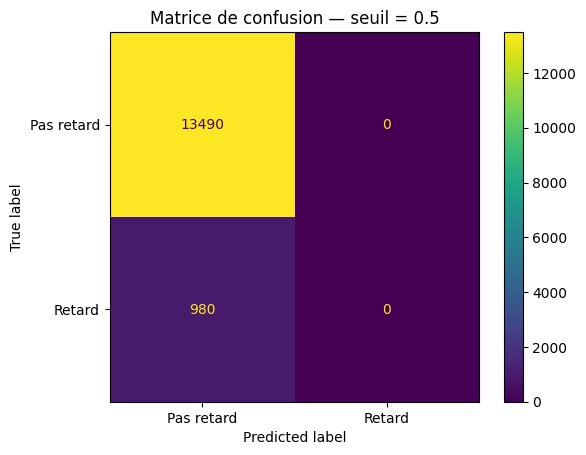

In [10]:
ConfusionMatrixDisplay.from_predictions(
    y_val, pred_val, display_labels=["Pas retard", "Retard"], values_format="d")
plt.title("Matrice de confusion — seuil = 0.5")
plt.show()

**Q11.** Dans notre problème, que représente un faux négatif ?

**Q12.** Que représente un faux positif ?

**Q13.** Si l'objectif est de détecter davantage de vrais retards, quel type d'erreur cherche-t-on en priorité à réduire ?

### ✅ Correction — Q11 à Q13

**Q11.** Un **faux négatif (FN)** est une commande réellement en retard que le modèle classe comme « pas retard ». L'entreprise ne déclenche donc pas d'alerte alors qu'un retard se produit.

**Q12.** Un **faux positif (FP)** est une commande finalement livrée à temps que le modèle signale comme présentant un risque de retard. Une action préventive peut alors être déclenchée inutilement.

**Q13.** Si l'objectif est de détecter davantage de vrais retards, il faut réduire les **faux négatifs**, donc augmenter le **rappel**.


## 8. Le seuil est une décision

In [11]:
thresholds = [0.50, 0.30, 0.20, 0.10, 0.075, 0.05]
results = []
for t in thresholds:
    pred = (proba_val >= t).astype(int)
    results.append({
        "threshold": t,
        "accuracy": accuracy_score(y_val, pred),
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0),
        "n_alerts": pred.sum()
    })
threshold_results = pd.DataFrame(results)
threshold_results

,threshold,accuracy,precision,recall,f1,n_alerts
0,0.500,0.932274,0.000000,0.000000,0.000000,0
1,0.300,0.932135,0.250000,0.001020,0.002033,4
2,0.200,0.927920,0.239669,0.029592,0.052679,121
3,0.100,0.814582,0.142377,0.345918,0.201726,2381
4,0.075,0.659848,0.112466,0.583673,0.188592,5086
5,0.050,0.406220,0.085854,0.805102,0.155162,9190


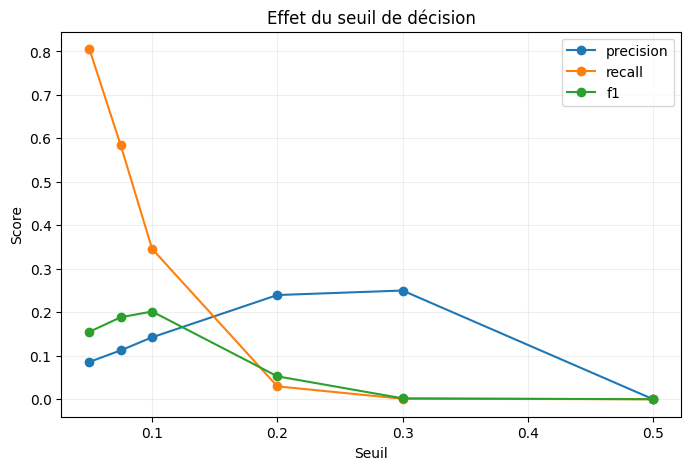

In [12]:
plt.figure(figsize=(8,5))
for metric in ["precision", "recall", "f1"]:
    plt.plot(threshold_results["threshold"], threshold_results[metric],
             marker="o", label=metric)
plt.xlabel("Seuil")
plt.ylabel("Score")
plt.title("Effet du seuil de décision")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

**Q14.** Que devient le rappel lorsque le seuil diminue ?

**Q15.** Que devient généralement la précision ?

**Q16.** Pourquoi ne peut-on pas choisir un seuil uniquement en maximisant le rappel ?

**Q17.** Si l'entreprise peut traiter un nombre limité d'alertes, quelle information supplémentaire faut-il considérer ?

### ✅ Correction — Q14 à Q17

**Q14.** Lorsque le seuil diminue, davantage de commandes sont classées positives et le **rappel augmente** : il passe ici de `0` au seuil `0.5` à environ **34,6 %** au seuil `0.10`, puis **58,4 %** au seuil `0.075`.

**Q15.** En contrepartie, la **précision tend à diminuer**, car davantage de commandes non retardées déclenchent également une alerte. Au seuil `0.10`, elle vaut environ **14,2 %**.

**Q16.** Maximiser uniquement le rappel pourrait conduire à classer presque toutes les commandes comme à risque. On détecterait alors la plupart des retards, mais au prix d'un très grand nombre de faux positifs.

**Q17.** Il faut notamment connaître le **coût ou la capacité de traitement des alertes** : nombre d'alertes que les équipes peuvent gérer, coût d'un faux positif, coût d'un faux négatif et conséquences métier d'un retard non anticipé.


## 9. Évaluer sans fixer un seuil unique
Étudions ROC et Precision-Recall.

ROC-AUC : 0.667
Average Precision : 0.13


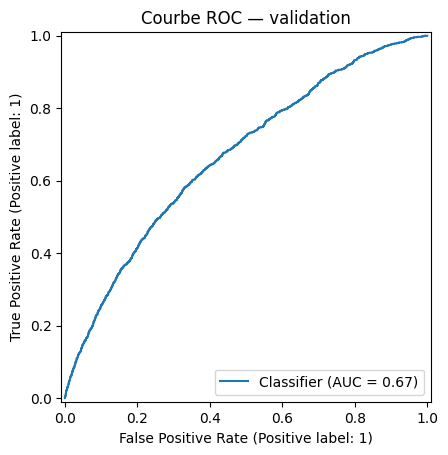

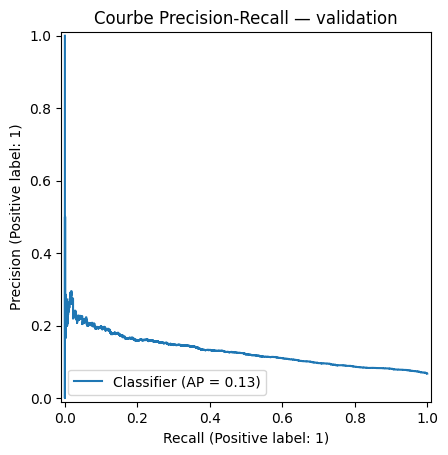

In [13]:
print("ROC-AUC :", round(roc_auc_score(y_val, proba_val), 3))
print("Average Precision :", round(average_precision_score(y_val, proba_val), 3))

RocCurveDisplay.from_predictions(y_val, proba_val)
plt.title("Courbe ROC — validation")
plt.show()

PrecisionRecallDisplay.from_predictions(y_val, proba_val)
plt.title("Courbe Precision-Recall — validation")
plt.show()

**Q18.** Pourquoi ces courbes apportent-elles une information différente des métriques calculées au seuil `0.5` ?

**Q19.** Pourquoi Precision-Recall est-elle particulièrement intéressante lorsque la classe positive est rare ?

### ✅ Correction — Q18 et Q19

**Q18.** Les métriques calculées à un seuil donné décrivent une seule règle de décision. Les courbes ROC et Precision-Recall étudient au contraire le comportement du modèle lorsque le seuil varie. Elles évaluent donc davantage la capacité du score produit par le modèle à séparer ou classer les observations.

Ici, le modèle a une **ROC-AUC d'environ 0,667** et une **Average Precision d'environ 0,130**, alors même qu'au seuil `0.5` son rappel est nul.

**Q19.** Lorsque la classe positive est rare, la courbe Precision-Recall met directement l'accent sur la classe d'intérêt : elle montre le compromis entre la proportion de vrais retards détectés (**rappel**) et la proportion d'alertes qui correspondent réellement à des retards (**précision**). Elle est donc particulièrement informative dans ce problème déséquilibré.


# 10. Agir sur le déséquilibre des classes

Nous modifions **uniquement le jeu d'entraînement**.

> **Validation et test ne sont jamais rééquilibrés.**

Ils doivent conserver la distribution réelle.

In [14]:
X_train_prepared = numeric_preprocessor.fit_transform(X_train)
X_val_prepared = numeric_preprocessor.transform(X_val)

print("Avant rééchantillonnage :")
print(y_train.value_counts())

Avant rééchantillonnage :
is_late
0    62955
1     4574
Name: count, dtype: int64


## 11. Random Oversampling et Random Undersampling
L'oversampling duplique des observations minoritaires, l'undersampling retire des observations majoritaires.

In [15]:
samplers = {
    "Naturel": None,
    "Random oversampling": RandomOverSampler(random_state=RANDOM_STATE),
    "Random undersampling": RandomUnderSampler(random_state=RANDOM_STATE)
}
sampling_results = []

for name, sampler in samplers.items():
    if sampler is None:
        X_res, y_res = X_train_prepared, y_train.to_numpy()
    else:
        X_res, y_res = sampler.fit_resample(X_train_prepared, y_train)

    model = LogisticRegression(max_iter=1000)
    model.fit(X_res, y_res)
    proba = model.predict_proba(X_val_prepared)[:,1]
    pred = (proba >= 0.5).astype(int)

    sampling_results.append({
        "méthode": name, "n_train": len(y_res),
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_val, proba),
        "average_precision": average_precision_score(y_val, proba)
    })

pd.DataFrame(sampling_results)

,méthode,n_train,precision,recall,f1,roc_auc,average_precision
0,Naturel,67529,0.000000,0.000000,0.000000,0.667036,0.129658
1,Random oversampling,125910,0.104625,0.669388,0.180966,0.669104,0.124925
2,Random undersampling,9148,0.104435,0.670408,0.180718,0.669522,0.124178


**Q20.** Comment le comportement du classifieur change-t-il ?

**Q21.** Le rééquilibrage améliore-t-il toutes les métriques simultanément ?

**Q22.** Pourquoi mesurer les performances sur la validation non rééquilibrée ?

### ✅ Correction — Q20 à Q22

**Q20.** Le comportement change fortement. Au seuil `0.5`, le modèle naturel ne détecte aucun retard, tandis que l'oversampling et l'undersampling conduisent à un rappel d'environ **67 %**. Le modèle produit donc beaucoup plus d'alertes.

**Q21.** Non. Le rappel augmente fortement, mais la précision n'est que d'environ **10,4 %** et l'Average Precision diminue légèrement. Rééquilibrer les classes modifie donc le compromis entre les erreurs ; cela n'améliore pas automatiquement toutes les dimensions de la performance.

**Q22.** La validation doit conserver la distribution réelle des commandes. Si nous la rééquilibrions également, les métriques ne représenteraient plus les performances attendues dans les conditions réelles d'utilisation. Le rééchantillonnage est une intervention sur **l'apprentissage**, pas sur la réalité à évaluer.


# 12. SMOTE : créer de nouvelles observations
SMOTE ne se contente pas de dupliquer des observations : il crée des observations synthétiques à partir d'observations minoritaires existantes.

In [17]:
smote = SMOTE(random_state=RANDOM_STATE)
X_smote, y_smote = smote.fit_resample(X_train_prepared, y_train)

print("Taille avant SMOTE :", len(y_train))
print("Taille après SMOTE :", len(y_smote))
print(pd.Series(y_smote).value_counts())

smote_model = LogisticRegression(max_iter=1000)
smote_model.fit(X_smote, y_smote)

proba_smote = smote_model.predict_proba(X_val_prepared)[:,1]
pred_smote = (proba_smote >= 0.5).astype(int)

display(classification_metrics(y_val, pred_smote))
print("ROC-AUC :", round(roc_auc_score(y_val, proba_smote), 3))
print("Average Precision :", round(average_precision_score(y_val, proba_smote), 3))

Taille avant SMOTE : 67529
Taille après SMOTE : 125910
is_late
0    62955
1    62955
Name: count, dtype: int64


,0
accuracy,0.595923
precision,0.104502
recall,0.656122
f1,0.180289


ROC-AUC : 0.671
Average Precision : 0.126


**Q23.** Comparez SMOTE aux méthodes précédentes. Observez-vous une amélioration systématique ?

**Q24.** Davantage d'observations d'entraînement signifie-t-il nécessairement davantage d'information réelle ?

### ✅ Correction — Q23 et Q24

**Q23.** SMOTE produit ici un rappel d'environ **65,6 %**, une précision d'environ **10,5 %**, une ROC-AUC d'environ **0,671** et une Average Precision d'environ **0,126**. Ces résultats sont très proches de ceux obtenus avec les méthodes aléatoires de rééchantillonnage. Il n'y a donc pas d'amélioration systématique ou spectaculaire liée à SMOTE.

**Q24.** Non. Après SMOTE, le jeu d'apprentissage contient davantage de lignes, mais les nouvelles lignes sont **synthétiques** : elles sont calculées à partir d'observations existantes. Nous avons modifié la représentation de la classe minoritaire sans collecter de nouvelles commandes réelles.


## 13. Que fabrique réellement SMOTE ?
Pour visualiser le phénomène, construisons une expérience en deux dimensions. Cette représentation est volontairement simplifiée.

In [18]:
smote_features = ["promised_delivery_days", "seller_customer_distance_mean"]

imp2 = SimpleImputer(strategy="median")
sc2 = StandardScaler()
X2 = sc2.fit_transform(imp2.fit_transform(train[smote_features]))
y2 = train[target].to_numpy()

X2_smote, y2_smote = SMOTE(random_state=RANDOM_STATE).fit_resample(X2, y2)
X2_synthetic = X2_smote[len(X2):]

print("Observations originales :", len(X2))
print("Observations synthétiques :", len(X2_synthetic))

Observations originales : 67529
Observations synthétiques : 58381


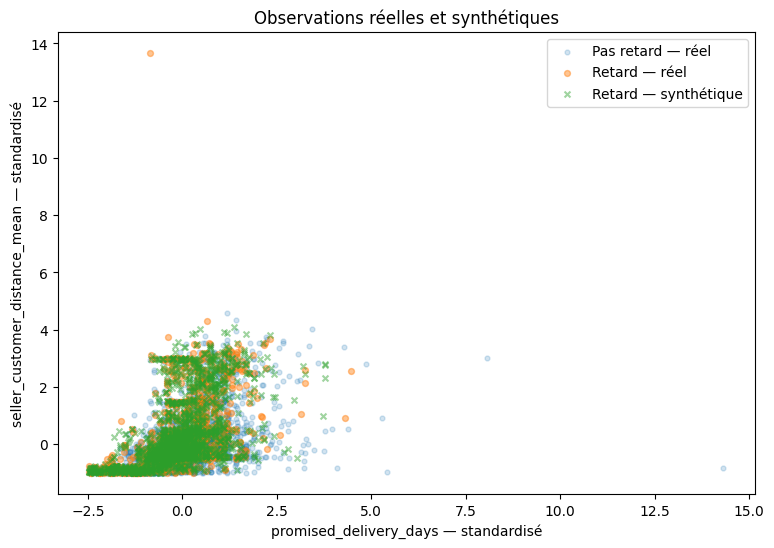

In [19]:
rng = np.random.default_rng(RANDOM_STATE)
maj = np.where(y2 == 0)[0]
mino = np.where(y2 == 1)[0]

maj_s = rng.choice(maj, min(2500, len(maj)), replace=False)
min_s = rng.choice(mino, min(1200, len(mino)), replace=False)
syn_s = rng.choice(len(X2_synthetic), min(2000, len(X2_synthetic)), replace=False)

plt.figure(figsize=(9,6))
plt.scatter(X2[maj_s,0], X2[maj_s,1], alpha=.20, s=12, label="Pas retard — réel")
plt.scatter(X2[min_s,0], X2[min_s,1], alpha=.45, s=18, label="Retard — réel")
plt.scatter(X2_synthetic[syn_s,0], X2_synthetic[syn_s,1], alpha=.45, s=18,
            marker="x", label="Retard — synthétique")
plt.xlabel("promised_delivery_days — standardisé")
plt.ylabel("seller_customer_distance_mean — standardisé")
plt.title("Observations réelles et synthétiques")
plt.legend()
plt.show()

**Q25.** Où se situent les observations synthétiques par rapport aux vrais retards ?

**Q26.** Certaines apparaissent-elles dans des régions également occupées par des commandes `pas retard` ?

**Q27.** Quelles conséquences cela pourrait-il avoir sur la frontière de décision ?

### ✅ Correction — Q25 à Q27

**Q25.** Les observations synthétiques apparaissent entre ou à proximité d'observations réelles appartenant à la classe « retard ». C'est cohérent avec le principe d'interpolation utilisé par SMOTE.

**Q26.** Oui. Certaines sont également situées dans des régions occupées par des commandes réellement livrées à temps. Les deux classes se chevauchent déjà dans cet espace de variables.

**Q27.** Ces points synthétiques peuvent accentuer l'occupation de régions ambiguës. Le classifieur peut alors déplacer sa frontière de décision pour englober davantage de ces zones, ce qui peut augmenter le nombre de faux positifs. SMOTE ne crée donc pas nécessairement une séparation plus nette entre les classes.


## 14. Quantifier l'ambiguïté locale
Dans l'espace numérique complet, comparons pour un échantillon de points synthétiques la distance au retard réel le plus proche et au `pas retard` réel le plus proche.

In [20]:
X_original = X_train_prepared
y_original = y_train.to_numpy()

X_real_late = X_original[y_original == 1]
X_real_not_late = X_original[y_original == 0]
X_synthetic = X_smote[len(X_original):]

rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(X_synthetic), min(5000, len(X_synthetic)), replace=False)
X_syn_sample = X_synthetic[idx]

nn_late = NearestNeighbors(n_neighbors=1).fit(X_real_late)
nn_not = NearestNeighbors(n_neighbors=1).fit(X_real_not_late)

d_late = nn_late.kneighbors(X_syn_sample)[0].ravel()
d_not = nn_not.kneighbors(X_syn_sample)[0].ravel()

ambiguity = pd.DataFrame({
    "distance_retard": d_late,
    "distance_pas_retard": d_not
})
ambiguity.head()

,distance_retard,distance_pas_retard
0,0.287522,0.645050
1,0.870616,1.017357
2,1.033575,0.634981
3,0.132549,0.412458
4,0.010945,1.207724


In [21]:
share = (ambiguity["distance_pas_retard"] < ambiguity["distance_retard"]).mean()
print("Points synthétiques plus proches d'un pas-retard réel que d'un retard réel :",
      round(100*share, 2), "%")

Points synthétiques plus proches d'un pas-retard réel que d'un retard réel : 4.56 %


**Q28.** Comment interprétez-vous ce résultat ?

**Q29.** Pourquoi cette expérience empêche-t-elle de considérer SMOTE comme une solution automatique au déséquilibre ?

### ✅ Correction — Q28 et Q29

**Q28.** Dans notre expérience, environ **4,56 %** des points synthétiques étudiés sont plus proches d'une observation réelle `pas retard` que d'une observation réelle `retard`. Cela montre que certains points fabriqués par SMOTE se trouvent dans un voisinage local particulièrement ambigu.

Cette mesure n'établit pas qu'un point synthétique est « faux » : elle met en évidence le chevauchement géométrique des classes.

**Q29.** SMOTE interpole entre des observations minoritaires ; il ne découvre pas de nouvelles commandes réelles et ne garantit pas que la région interpolée soit exclusivement associée aux retards. Son effet doit donc être évalué sur des données non rééchantillonnées plutôt que supposé bénéfique a priori.


## 15. Et les variables catégorielles ?

Après One-Hot Encoding, deux paiements peuvent être représentés ainsi :

```text
credit_card    boleto
    1             0
    0             1
```

Une interpolation numérique naïve pourrait produire :

```text
credit_card    boleto
   0.4           0.6
```

**Q30.** Cette observation correspond-elle directement à une modalité réelle de paiement ?

**Q31.** Quelle limite supplémentaire cela met-il en évidence pour SMOTE après One-Hot Encoding ?

### ✅ Correction — Q30 et Q31

**Q30.** Non. Une représentation telle que `credit_card = 0.4` et `boleto = 0.6` ne correspond pas directement à une modalité réelle de paiement : une commande n'est pas payée « à 40 % par la modalité credit card et à 60 % par boleto » au sens de la variable catégorielle initiale.

**Q31.** Une application naïve de SMOTE après One-Hot Encoding peut donc créer des vecteurs intermédiaires qui n'ont pas de signification métier directe. C'est une **limite sémantique** qui s'ajoute à la limite géométrique étudiée précédemment. Pour des données mixtes, une méthode adaptée comme `SMOTENC` peut être envisagée, mais elle doit elle aussi être validée expérimentalement.


# 16. Choisir une stratégie

**Q32.** Parmi les stratégies expérimentées, laquelle retiendriez-vous ?

**Q33.** Quel seuil choisiriez-vous ?

**Q34.** Justifiez votre décision à partir des métriques observées et du coût métier des faux positifs et faux négatifs.

### ✅ Correction — Q32 à Q34

**Q32.** Ici, je retiendrais la **régression logistique entraînée sur la distribution naturelle**, sans rééchantillonnage. Les méthodes de sampling augmentent fortement le rappel au seuil `0.5`, mais leur précision reste autour de 10,5 % et elles n'améliorent pas clairement ROC-AUC ou Average Precision. Le réglage du seuil permet déjà d'adapter la décision sans modifier artificiellement la distribution d'apprentissage.

**Q33.** Parmi les seuils testés, je retiendrais ici **`0.10`** comme choix pédagogique et opérationnel raisonnable.

**Q34.** Au seuil `0.10`, le modèle naturel atteint environ **34,6 % de rappel**, **14,2 % de précision** et un **F1-score de 0,202**, avec **2 381 alertes** sur la validation. C'est le meilleur F1 parmi les seuils testés et il produit nettement moins d'alertes que le seuil `0.075` (5 086 alertes). Ce choix privilégie donc un compromis entre détection des retards et charge opérationnelle.

Ce n'est pas un seuil universellement « optimal » : avec un coût très élevé des faux négatifs, l'entreprise pourrait légitimement retenir un seuil plus bas.


# 17. Évaluation finale
Une fois la stratégie et le seuil choisis sur validation, utilisez le test **une seule fois**.

In [ ]:
# CORRECTION — application finale au jeu de test
#
# Choix effectué sur la validation :
# - distribution naturelle (pas de rééchantillonnage)
# - seuil = 0.10

chosen_threshold = 0.10

# 1. Regrouper train et validation.
train_validation = pd.concat(
    [train, validation],
    ignore_index=True
)

# 2. Reconstruire X et y.
X_train_validation = train_validation[features]
y_train_validation = train_validation[target]

X_test_final = test[features]
y_test_final = test[target]

# 3. Refaire le prétraitement sur train + validation.
# Aucun rééchantillonnage n'est appliqué puisque nous avons retenu
# la distribution naturelle.
final_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_train_validation_prepared = final_preprocessor.fit_transform(
    X_train_validation
)

# Le test n'est jamais utilisé pour ajuster le prétraitement.
X_test_prepared = final_preprocessor.transform(
    X_test_final
)

# 4. Réentraîner la régression logistique sur train + validation.
final_model = LogisticRegression(max_iter=1000)

final_model.fit(
    X_train_validation_prepared,
    y_train_validation
)

# 5. Calculer les probabilités sur le test.
proba_test = final_model.predict_proba(
    X_test_prepared
)[:, 1]

# 6. Appliquer au test le seuil choisi précédemment sur validation.
pred_test = (
    proba_test >= chosen_threshold
).astype(int)

# 7. Calculer les métriques finales.
final_results = classification_metrics(
    y_test_final,
    pred_test
)

final_results["roc_auc"] = roc_auc_score(
    y_test_final,
    proba_test
)

final_results["average_precision"] = average_precision_score(
    y_test_final,
    proba_test
)

print("Stratégie retenue : distribution naturelle")
print("Seuil retenu :", chosen_threshold)
print("Nombre d'alertes :", pred_test.sum())
print()
display(final_results)

# Matrice de confusion finale
ConfusionMatrixDisplay.from_predictions(
    y_test_final,
    pred_test,
    display_labels=["Pas retard", "Retard"],
    values_format="d"
)

plt.title(
    f"Matrice de confusion finale — seuil = {chosen_threshold}"
)
plt.show()


### Dernière analyse

**Q35.** Les performances test sont-elles proches de celles observées sur validation ?

**Q36.** Pourquoi ne faut-il pas modifier le seuil après avoir observé le test ?

**Q37.** Quelles décisions relevaient de l'apprentissage du modèle et lesquelles relevaient de la décision métier ?

### ✅ Correction — Q35 à Q37

**Q35.** Après exécution de la cellule précédente, les performances test doivent être comparées à celles obtenues sur validation avec le **même seuil de `0.10`**. On ne cherche pas une égalité exacte : un écart d'échantillonnage est normal. Un écart important signalerait en revanche que notre estimation sur validation était instable ou que nos choix se sont trop adaptés à cette validation.

**Q36.** Modifier le seuil après avoir observé le test reviendrait à utiliser le test pour prendre une décision de modélisation. Il ne constituerait alors plus une évaluation indépendante. Le seuil doit être figé avant l'ouverture du test.

**Q37.** L'**apprentissage** concerne l'estimation des paramètres de la régression logistique à partir des données d'entraînement. Le choix d'un éventuel rééchantillonnage fait également partie du protocole d'apprentissage. Le **seuil**, lui, traduit la probabilité en action et dépend du compromis métier entre faux positifs, faux négatifs et capacité de traitement des alertes. La validation sert à comparer ces choix ; le test sert uniquement à l'évaluation finale.


# 18. Bilan

$$
\text{données}
\rightarrow
\text{probabilité}
\rightarrow
\text{seuil}
\rightarrow
\text{décision}
\rightarrow
\text{conséquences}
$$

À retenir :

- l'accuracy peut masquer l'échec sur la classe d'intérêt ;
- le seuil contrôle le compromis entre types d'erreurs ;
- précision et rappel répondent à des questions différentes ;
- ROC et Precision-Recall étudient le modèle au-delà d'un seuil unique ;
- le rééchantillonnage modifie ce que voit le modèle ;
- SMOTE peut aider mais aussi créer de l'ambiguïté lorsque les classes se chevauchent ;
- une observation synthétique n'est pas une observation réelle.

La question finale n'est donc pas seulement **« quel modèle prédit le mieux ? »**, mais aussi **« à partir de ces probabilités, quelle décision voulons-nous prendre ? »**